# 📊 RESUMO EXECUTIVO: ANÁLISE DE VENDAS E-COMMERCE de Eletrônicos no reabastecimento de estoque e campanhas de marketing.

### 1.  OBJETIVO DO PROJETO

Análise do desempenho de vendas de e-commerce para identificar gargalos financeiros, produtos campeões e oportunidades de expansão logística.

### 2.  PRINCIPAIS RESULTADOS

• **Saúde Financeira:** Faturamento bruto de **R$ 54.000,00**, com receita real aprovada de **R$ 44.100,00**.

• **Alerta Financeiro:** **R$ 5.900,00** em vendas canceladas e pendentes que impactam diretamente o fluxo de caixa.

• **Categoria Campeã:** **Eletrônicos** lidera as vendas com a maior participação de receita.

• **Geografia das Vendas:** **São Paulo (R$ 20.734,10)** e **Minas Gerais (R$ 11.703,00)** representam juntas mais da metade do faturamento total.

---

### 3.  RECOMENDAÇÕES ESTRATÉGICAS

1. **Investigação de Pagamentos:** Revisar o gateway de cartão e o processo de cobrança por boleto para reduzir o volume de cancelamentos e pendências.
2. **Eficiência Logística:** Avaliar opções de frete diferenciado ou centro de distribuição focado no Sudeste (SP e MG) para otimizar prazos.
3. **Foco de Estoque:** Priorizar a categoria de Eletrônicos no reabastecimento de estoque e campanhas de marketing.

In [1]:
from google.colab import drive


In [2]:
# Primeiro, montamos o Google Drive no diretório padrão (sem espaços)
drive.mount("/content/drive")

# Depois de montado, você pode ler o seu arquivo CSV usando o pandas:
# caminho_arquivo = "/content/drive/MyDrive/Projeto 1 /vendas_ecommerce.csv .csv"
# df = pd.read_csv(caminho_arquivo)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("/content/drive/MyDrive/Projeto 1 /vendas_ecommerce.csv .csv")

In [5]:
df.head()

,id_pedido,data_pedido,cliente,estado,categoria,produto,quantidade,preco_unitario,status_pagamento
0,1000,2024-01-01,Cliente 7,RS,Beleza,Kit Skincare,3,120.0,Aprovado
1,1001,2024-01-02,Cliente 23,MG,Casa e Decoração,Almofada Decorativa,5,35.0,Aprovado
2,1002,2024-01-03,Cliente 2,SP,Beleza,Perfume Importado,2,299.9,Aprovado
3,1003,2024-01-04,Cliente 22,RJ,Esportes,Tapete de Yoga,1,89.0,Aprovado
4,1004,2024-01-05,Cliente 28,MG,Casa e Decoração,Almofada Decorativa,4,NaN,Aprovado


In [6]:
df.shape


(150, 9)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_pedido         150 non-null    int64  
 1   data_pedido       150 non-null    object 
 2   cliente           150 non-null    object 
 3   estado            144 non-null    object 
 4   categoria         150 non-null    object 
 5   produto           150 non-null    object 
 6   quantidade        150 non-null    int64  
 7   preco_unitario    145 non-null    float64
 8   status_pagamento  150 non-null    object 
dtypes: float64(1), int64(2), object(6)
memory usage: 10.7+ KB


In [8]:
df.isnull().sum()

,0
id_pedido,0
data_pedido,0
cliente,0
estado,6
categoria,0
produto,0
quantidade,0
preco_unitario,5
status_pagamento,0


In [9]:
df[df['preco_unitario'].isnull()]

,id_pedido,data_pedido,cliente,estado,categoria,produto,quantidade,preco_unitario,status_pagamento
4,1004,2024-01-05,Cliente 28,MG,Casa e Decoração,Almofada Decorativa,4,NaN,Aprovado
16,1016,2024-01-17,Cliente 9,SP,Vestuário,Calça Jeans,4,NaN,Aprovado
36,1036,2024-02-06,Cliente 22,SP,Casa e Decoração,Luminária de Mesa,1,NaN,Aprovado
56,1056,2024-02-26,Cliente 25,SP,Esportes,Garrafa Térmica,4,NaN,Cancelado
80,1080,2024-03-21,Cliente 25,BA,Eletrônicos,Smartwatch,5,NaN,Pendente


In [10]:
# 1. Preenche os nulos do preço unitário com a média de cada produto e salva no DataFrame
df['preco_unitario'] = df['preco_unitario'].fillna(df.groupby('produto')['preco_unitario'].transform('mean'))

# 2. Conferir se zeramos os nulos de preco_unitario (corrigido o nome da coluna)
df['preco_unitario'].isnull().sum()

np.int64(0)

In [11]:
# 1. Preenche os nulos da coluna estado
df['estado'] = df['estado'].fillna('Não informado')

In [12]:
# 2. Conferir se zeramos TODOS os nulos do DataFrame
df.isnull().sum()

,0
id_pedido,0
data_pedido,0
cliente,0
estado,0
categoria,0
produto,0
quantidade,0
preco_unitario,0
status_pagamento,0


In [13]:
# 1. Cria a nova coluna calculando o faturamento total por pedido
df['faturamento_total'] = df['quantidade'] * df['preco_unitario']

In [14]:
# 2. Visualiza as primeiras 5 linhas para conferir a nova coluna no final da tabela
df.head()

,id_pedido,data_pedido,cliente,estado,categoria,produto,quantidade,preco_unitario,status_pagamento,faturamento_total
0,1000,2024-01-01,Cliente 7,RS,Beleza,Kit Skincare,3,120.0,Aprovado,360.0
1,1001,2024-01-02,Cliente 23,MG,Casa e Decoração,Almofada Decorativa,5,35.0,Aprovado,175.0
2,1002,2024-01-03,Cliente 2,SP,Beleza,Perfume Importado,2,299.9,Aprovado,599.8
3,1003,2024-01-04,Cliente 22,RJ,Esportes,Tapete de Yoga,1,89.0,Aprovado,89.0
4,1004,2024-01-05,Cliente 28,MG,Casa e Decoração,Almofada Decorativa,4,35.0,Aprovado,140.0


In [15]:
# 1. Faturamento Total Geral da Empresa
print("Faturamento Total Geral: R$", df['faturamento_total'].sum())

Faturamento Total Geral: R$ 54015.0


In [16]:
print("n--- Faturamento por Categoria ---")
# 2. Faturamento por Categoria
df.groupby('categoria')['faturamento_total'].sum()

n--- Faturamento por Categoria ---


,faturamento_total
categoria,
Beleza,12322.7
Casa e Decoração,3731.9
Eletrônicos,20198.6
Esportes,5617.6
Vestuário,12144.2


In [17]:
# Faturamento total por produto (ordenado do maior para o menor)
df.groupby('produto')['faturamento_total'].sum().sort_values(ascending=False)

,faturamento_total
produto,
Fone de Ouvido Bluetooth,9395.3
Smartwatch,8376.0
Perfume Importado,6897.7
Calça Jeans,5246.5
Jaqueta,4921.0
Kit Skincare,4320.0
Tapete de Yoga,3026.0
Carregador Rápido,2427.3
Camiseta Básica Algodão,1976.7


In [18]:
# Faturamento total por status de pagamento
df.groupby('status_pagamento')['faturamento_total'].sum()

,faturamento_total
status_pagamento,
Aprovado,44151.1
Cancelado,5931.7
Pendente,3932.2


In [19]:
# faturamento total por estado (do maior para o menor)
df.groupby('estado')['faturamento_total'].sum().sort_values(ascending=False)

,faturamento_total
estado,
SP,20734.1
MG,11703.0
PR,6110.1
RJ,5363.5
RS,4224.1
BA,3159.2
Não informado,1466.9
SC,1254.1


In [20]:
import matplotlib.pyplot as plt

In [21]:
# 1. Agrupar os dados por categoria e somar o faturamento
faturamento_por_categoria = df.groupby('categoria')['faturamento_total'].sum().sort_values(ascending=False)

### Gráfico de Faturamento por Categoria (Corrigido)

Unimos a criação das barras, a personalização dos títulos e a exibição do gráfico na mesma célula para garantir que tudo seja renderizado corretamente.

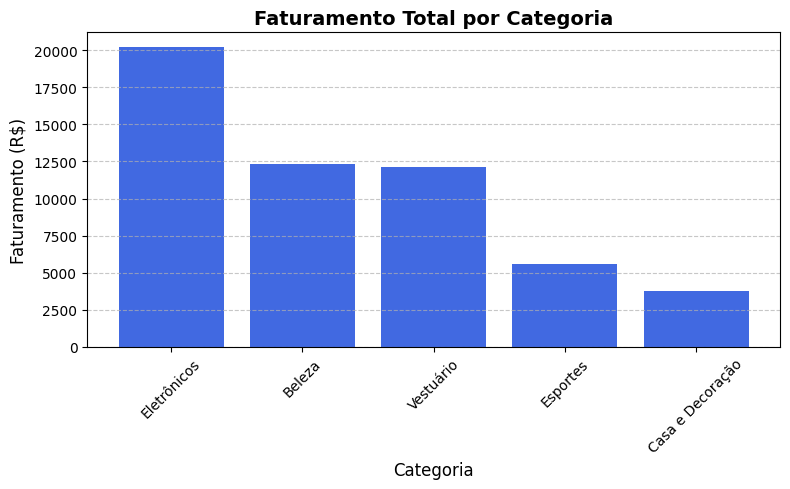

In [22]:
# Criar o gráfico de barras completo e formatado
plt.figure(figsize=(8, 5))
plt.bar(faturamento_por_categoria.index, faturamento_por_categoria.values, color='royalblue')

# Adicionar títulos e rótulos personalizados
plt.title('Faturamento Total por Categoria', fontsize=14, fontweight='bold')
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Exibir o gráfico unificado de forma organizada
plt.tight_layout()
plt.show()

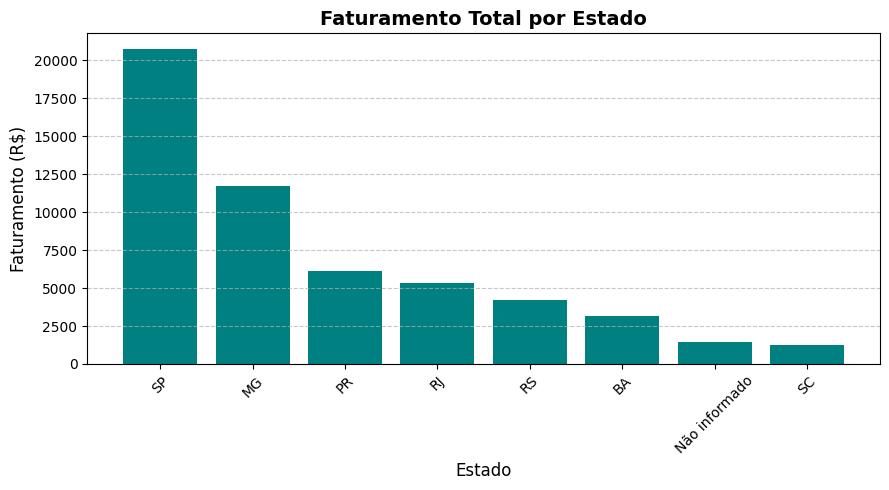

In [23]:
import matplotlib.pyplot as plt

# 1. Agrupar os dados por estado e somar o faturamento (do maior para o menor)
faturamento_por_estado = df.groupby('estado')['faturamento_total'].sum().sort_values(ascending=False)

# 2. Criar a figura e o gráfico de barras
plt.figure(figsize=(9, 5))
plt.bar(faturamento_por_estado.index, faturamento_por_estado.values, color='teal')

# 3. Adicionar títulos e rótulos personalizados
plt.title('Faturamento Total por Estado', fontsize=14, fontweight='bold')
plt.xlabel('Estado', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 4. Exibir o gráfico de forma organizada
plt.tight_layout()
plt.show()

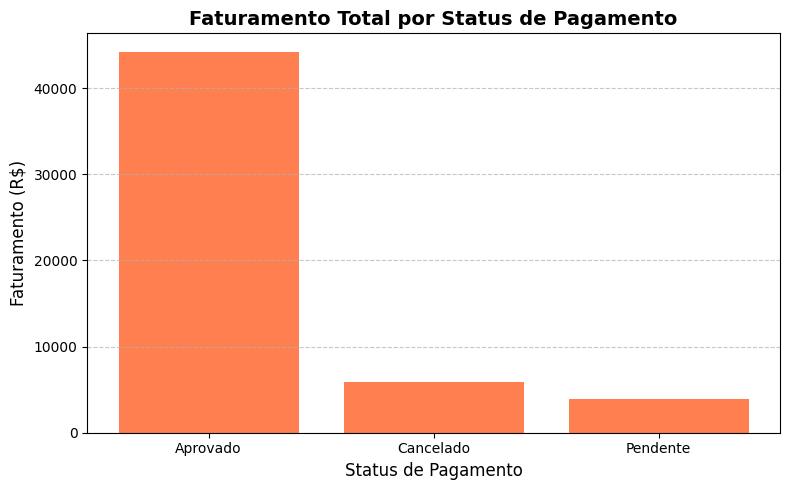

In [24]:
import matplotlib.pyplot as plt

# 1. Agrupar os dados por status de pagamento e somar o faturamento
faturamento_por_status = df.groupby('status_pagamento')['faturamento_total'].sum().sort_values(ascending=False)

# 2. Criar a figura com o mesmo padrão estético
plt.figure(figsize=(8, 5))
plt.bar(faturamento_por_status.index, faturamento_por_status.values, color='coral')

# 3. Adicionar títulos e rótulos personalizados seguindo a mesma identidade visual
plt.title('Faturamento Total por Status de Pagamento', fontsize=14, fontweight='bold')
plt.xlabel('Status de Pagamento', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=0)  # Mantém os nomes na horizontal por serem curtos
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 4. Exibir o gráfico de forma organizada
plt.tight_layout()
plt.show()